In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def order_points(pts):
    """
    Rearranges coordinates to order: 
    top-left, top-right, bottom-right, bottom-left
    """
    rect = np.zeros((4, 2), dtype="float32")
    s = pts.sum(axis=1)
    rect[0] = pts[np.argmin(s)]
    rect[2] = pts[np.argmax(s)]
    diff = np.diff(pts, axis=1)
    rect[1] = pts[np.argmin(diff)]
    rect[3] = pts[np.argmax(diff)]

    return rect

def four_point_transform(image, pts):
    """
    Applies the perspective transform to 'flatten' the image
    """
    rect = order_points(pts)
    (tl, tr, br, bl) = rect
    widthA = np.sqrt(((br[0] - bl[0]) ** 2) + ((br[1] - bl[1]) ** 2))
    widthB = np.sqrt(((tr[0] - tl[0]) ** 2) + ((tr[1] - tl[1]) ** 2))
    maxWidth = max(int(widthA), int(widthB))
    heightA = np.sqrt(((tr[0] - br[0]) ** 2) + ((tr[1] - br[1]) ** 2))
    heightB = np.sqrt(((tl[0] - bl[0]) ** 2) + ((tl[1] - bl[1]) ** 2))
    maxHeight = max(int(heightA), int(heightB))
    dst = np.array([
        [0, 0],
        [maxWidth - 1, 0],
        [maxWidth - 1, maxHeight - 1],
        [0, maxHeight - 1]], dtype="float32")

    M = cv2.getPerspectiveTransform(rect, dst)
    warped = cv2.warpPerspective(image, M, (maxWidth, maxHeight))

    return warped

In [13]:
def scan_document(image_path):
    image = cv2.imread(image_path)
    if image is None:
        print("Error: Image not found. Check the path.")
        return

    ratio = image.shape[0] / 500.0
    orig = image.copy()
    image = cv2.resize(image, (int(image.shape[1] / ratio), 500))
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    gray = cv2.GaussianBlur(gray, (5, 5), 0)
    edged = cv2.Canny(gray, 75, 200)
    cnts, _ = cv2.findContours(edged.copy(), cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE)
    cnts = sorted(cnts, key=cv2.contourArea, reverse=True)[:5] # Sort by largest area

    screenCnt = None

    for c in cnts:
        peri = cv2.arcLength(c, True)
        approx = cv2.approxPolyDP(c, 0.02 * peri, True)
        if len(approx) == 4:
            screenCnt = approx
            break

    if screenCnt is None:
        print("Could not find the document outline. Try a simpler background.")
        return

    warped = four_point_transform(orig, screenCnt.reshape(4, 2) * ratio)
    warped_gray = cv2.cvtColor(warped, cv2.COLOR_BGR2GRAY)
    T = cv2.threshold(warped_gray, 0, 255, cv2.THRESH_BINARY | cv2.THRESH_OTSU)[1]
    
    cv2.drawContours(image, [screenCnt], -1, (0, 255, 0), 2)

    plt.figure(figsize=(15, 10))

    plt.subplot(1, 3, 1)
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title("Detected Document")
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.imshow(warped_gray, cmap='gray')
    plt.title("Perspective Corrected")
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.imshow(T, cmap='gray')
    plt.title("Final Scanned Output")
    plt.axis('off')
    
    plt.show()
    

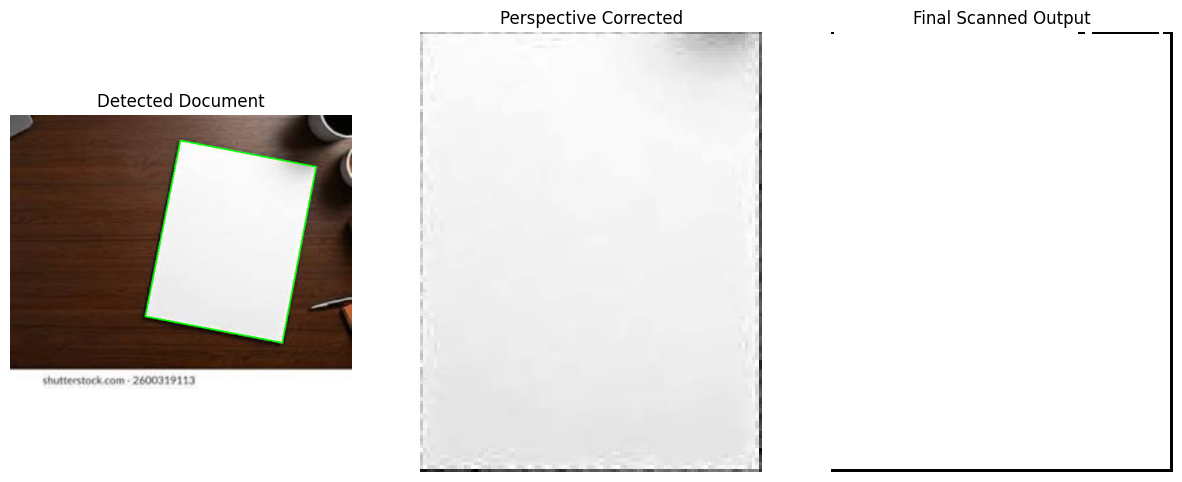

In [14]:
scan_document('paper.jpg')